In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(7)

num_notes = 40
sequence_length = 25
num_sequences = 1200

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))
print(data.shape)


(1200, 25)


• **Rows (1200):**  Represent the total number of individual musical sequences (samples) in the dataset.

• **Columns (25):** Represent the number of consecutive musical notes (time steps) in each sequence.


In [ ]:
x_train = data[:, :-1]
y_train = data[:, 1:]

x_train = to_categorical(x_train, num_classes=num_notes)
y_train = to_categorical(y_train, num_classes=num_notes)

print("x_train :", x_train.shape, " y_train :", y_train.shape)


x_train : (1200, 24, 40)  y_train : (1200, 24, 40)


• Shifting the target left by one aligns each input note \(x_{t}\) with the immediate next note \(y_t = x_{t+1}\).

• This sets up a many-to-many next-token prediction (language modeling) task, where the model predicts the next note at every time step.


In [ ]:
model = models.Sequential([
    layers.Input(shape=(24, 40)),
    layers.Bidirectional(layers.LSTM(100, return_sequences=True)),
    layers.Bidirectional(layers.LSTM(100, return_sequences=True)),
    layers.TimeDistributed(layers.Dense(40, activation='softmax'))
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 24, 200)        │       112,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 24, 200)        │       240,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 40)         │         8,040 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,640 (1.38 MB)

 Trainable params: 361,640 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

• **200 features per step:** A Bidirectional wrapper runs two independent 100-unit LSTMs (one forward and one backward) and concatenates their hidden states (\(100 + 100 = 200\)) at every time step.

• **TimeDistributed:** Applies the exact same Dense(40) classifier with shared weights independently to each of the 24 time steps, converting each 200-dimensional vector into a 40-note probability distribution.


In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 83ms/step - accuracy: 0.0982 - loss: 3.6600 - val_accuracy: 0.1568 - val_loss: 3.6188
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1516 - loss: 3.5359 - val_accuracy: 0.1222 - val_loss: 3.4060
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1395 - loss: 3.2537 - val_accuracy: 0.1618 - val_loss: 3.1308
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1837 - loss: 2.9653 - val_accuracy: 0.2089 - val_loss: 2.8261
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.2454 - loss: 2.6235 - val_accuracy: 0.2825 - val_loss: 2.4656
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3157 - loss: 2.2524 - val_accuracy: 0.3582 - val_loss: 2.0957
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.3994 - loss: 1.8932 - val_accuracy: 0.4451 - val_loss: 1.7437
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4915 - loss: 1.5593 - val_accuracy: 0.5495 - 

categorical_crossentropy is the required loss function for multi-class classification when the ground-truth targets (y_train) are **one-hot encoded** vectors across mutually exclusive classes (40 possible notes).

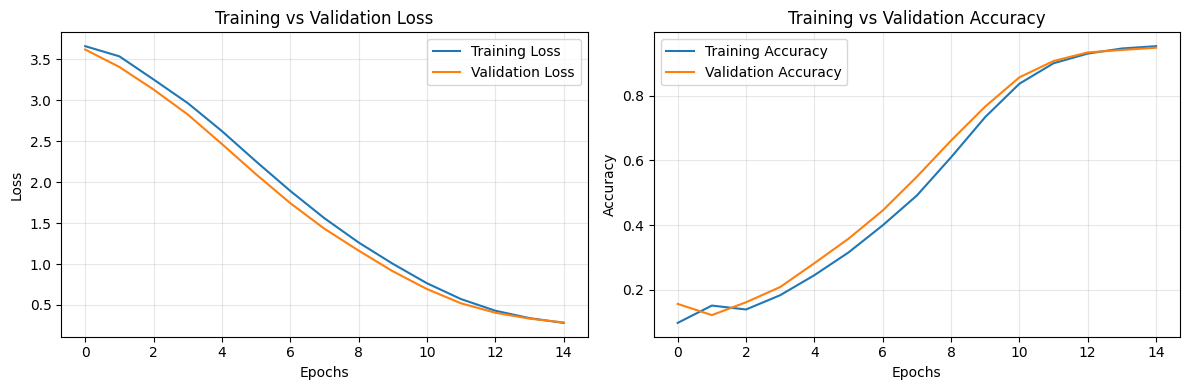

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss curve
ax1.plot(history.history['loss'], label='Training Loss')
ax1.plot(history.history['val_loss'], label='Validation Loss')
ax1.set_title('Training vs Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Accuracy curve
ax2.plot(history.history['accuracy'], label='Training Accuracy')
ax2.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax2.set_title('Training vs Validation Accuracy')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


• Yes, the training and validation curves stay very close together throughout training.
• A large gap (where training accuracy is high and loss is low, while validation accuracy stalls and validation loss rises) would indicate **overfitting**—meaning the model memorized the training samples instead of generalizing.

In [ ]:
def generate_music(model, start_sequence, num_generated_notes=40):
    generated = []
    current = start_sequence.copy()

    for _ in range(num_generated_notes):
        pred = model.predict(current, verbose=0)
        next_note = np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        new_note_one_hot = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current = np.concatenate([current[:, 1:, :], new_note_one_hot], axis=1)

    return generated

# Create a random one-hot seed window of shape (1, 24, 40)
random_seed_indices = np.random.randint(0, num_notes, size=(1, 24))
seed_window = to_categorical(random_seed_indices, num_classes=num_notes)

generated_notes = generate_music(model, seed_window, num_generated_notes=40)
print("Generated :", generated_notes)


Generated : [26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26]


• **Time-step kept:** At each iteration, we keep only the prediction from the last time step (pred[:, -1, :]).

• **Window update:** We drop the oldest note at index 0 (current[:, 1:, :]) and append the one-hot encoded newly predicted note to the end of the sequence (axis=1).

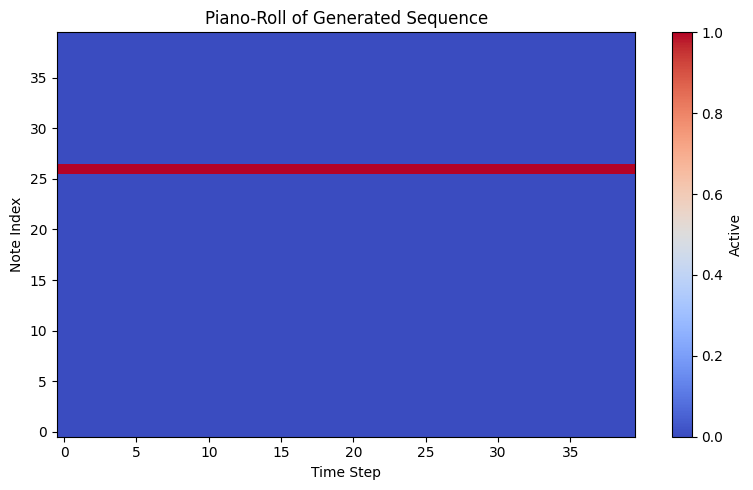

In [ ]:
piano_roll = np.zeros((40, 40))

for t, note in enumerate(generated_notes):
    piano_roll[note, t] = 1

plt.figure(figsize=(8, 5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower')
plt.colorbar(label='Active')
plt.title('Piano-Roll of Generated Sequence')
plt.xlabel('Time Step')
plt.ylabel('Note Index')
plt.tight_layout()
plt.show()

• **One column:** Represents a single time step (one generated note position from 0 to 39).

• **One active cell:** Because np.argmax picks exactly one deterministic note (monophonic output) at each step, only that single note index is set to 1 while the other 39 remain 0.

**Label leakage:** Because the target at step \(t\) is the input at step \(t+1\), the backward pass of the Bidirectional LSTM already reads \(x_{t+1}\) and directly copies the answer instead of learning musical structure.